# Semantic Search: Retrieval Quality vs. Speed
**Joe Williams · Completed Colab experiment · November 18, 2026**

The full run is complete: 50 development queries, all 300 official test queries, and three fixed retrieval pipelines. All 13 executed code cells and numerical outputs are retained.

This project extends Chapter 8 of *Hands-On Large Language Models* by Jay Alammar and Maarten Grootendorst. Result interpretation was added after execution; the original code is unchanged.

To inspect the experiment, read the saved outputs. For a new experiment, use a separate copy in a fresh Colab T4 runtime and choose Run all. No API key is required. A new run creates a separate result directory.


## Recorded results

Quality was evaluated on **all 300 official test queries** against **5,183 documents**. Each query receives
equal weight. Higher quality scores are better; these retrieval metrics are not classification accuracy.

| Pipeline | nDCG@10 | MRR@10 | Recall@5 | Recall@10 | Recall@50 |
|---|---:|---:|---:|---:|---:|
| BM25 | 0.6519 | 0.6186 | 0.7284 | 0.7740 | 0.8657 |
| Dense embeddings | 0.6451 | 0.6047 | 0.7379 | 0.7833 | 0.8920 |
| BM25 + reranker | 0.6818 | 0.6529 | 0.7301 | 0.8029 | 0.8657 |

Warm latency was measured separately on **20 development queries × 3 repeats per pipeline**, with randomized
trial order and synchronized GPU timing. Lower time is better; p95 is a latency percentile, not an uncertainty interval.

| Pipeline | Median (ms) | p95 (ms) | Trials |
|---|---:|---:|---:|
| BM25 | 26.32 | 44.93 | 60 |
| Dense embeddings | 12.74 | 20.23 | 60 |
| BM25 + reranker | 310.25 | 348.62 | 60 |

Reranking produced the highest test nDCG@10, improving over BM25 by **0.0299**, while requiring
**11.79×** its median query time. Dense retrieval was fastest, but its nDCG@10 was **0.0068 lower**
than BM25's. Dense retrieval had the highest Recall@5 and Recall@50. No pipeline dominates every quality measure.

BM25 and BM25 + reranker have identical Recall@50 (**0.8657**) because they contain exactly the same 50 candidates.
Reranking changes order; it cannot add a missed document. Its mean gain includes **60 improved, 47 worsened,
and 193 tied** test queries on nDCG@10.

![Test quality and warm development-query latency](results/search_20261118T185027Z-4f8afe/quality_latency.png)

## Uncertainty and practical interpretation

Intervals use 2,000 paired query-bootstrap resamples with seed 2026.

| Comparison | Mean nDCG@10 change | Paired 95% interval | Improved / worsened / tied queries |
|---|---:|---|---|
| Dense embeddings minus BM25 | -0.0068 | [-0.0454, +0.0308] | 70 / 71 / 159 |
| BM25 + reranker minus BM25 | +0.0299 | [+0.0014, +0.0578] | 60 / 47 / 193 |
| BM25 + reranker minus Dense embeddings | +0.0367 | [+0.0021, +0.0739] | 78 / 57 / 165 |

The dense-versus-BM25 interval spans zero. The two reranking intervals are above zero in this recorded
bootstrap analysis, with lower bounds close to zero. They support a conditional descriptive comparison,
not a guarantee across datasets or a claim that reranking helps every query.

For this run, dense retrieval offers the lowest warm latency; reranking offers the highest primary
retrieval score at substantially greater query time. A deployment choice would require a latency budget,
the cost of missed evidence, and representative target-domain queries.


## 1. Install the experiment dependencies
Use a fresh runtime so older imports do not remain in memory after installation. PyTorch
is supplied by Colab; this cell leaves its GPU build in place. The main model libraries
are pinned, and the actual environment is saved with the results.

In [1]:
import subprocess
import sys

# Install the supported model/scoring versions before importing them.
packages = [
    "sentence-transformers==5.1.2", "transformers==4.57.6",
    "huggingface-hub==0.36.2", "rank-bm25==0.2.2", "threadpoolctl==3.6.0",
    "numpy>=1.26,<3", "pandas>=2,<3", "pyarrow>=14,<27", "matplotlib>=3.7,<4",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])

0

## 2. Fix the experiment before looking at test results

| Pipeline | What happens for each query? | Main trade-off |
|---|---|---|
| BM25 | Tokenize the query and score word matches across all documents. | Fast lexical baseline; may miss paraphrases. |
| Dense | Encode the query and compare it with every normalized document vector. | Can match meaning; requires model inference and a stored embedding matrix. |
| BM25 + reranker | Retrieve BM25's top 50, then score each query/document pair with a cross-encoder. | More computation; cannot recover documents outside those 50. |

The primary score is **nDCG@10**. Candidate size, models, token limits, and BM25 settings
are fixed here. Every pipeline sees the same title-plus-abstract documents. Neural models
have token limits, so their truncation is audited and reported; BM25 reads the full text.
This is a comparison of these complete configurations, not an isolated architecture test.

Development examples come from the official training judgments. Exact normalized query
text shared with test is excluded from the development pool. All 300 official test query
IDs are preserved. No test-driven parameter selection is performed. Shared corpus documents
across query splits are expected in document retrieval. Pretraining exposure is not audited.

In [2]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import json
import random
import shutil
import uuid
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from threadpoolctl import threadpool_limits

# Fixed choices, recorded before retrieval or evaluation.
CONFIG = {'seed': 2026,
 'dataset_id': 'BeIR/scifact',
 'dataset_revision': 'b3b5335604bf5ee3c4447671af975ea25143d4f5',
 'qrels_id': 'BeIR/scifact-qrels',
 'qrels_revision': '2938d17dc3b09882fdb8c12bbbe2e2dc0e75a029',
 'embedding_model': 'sentence-transformers/all-MiniLM-L6-v2',
 'embedding_revision': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41',
 'reranker_model': 'cross-encoder/ms-marco-MiniLM-L6-v2',
 'reranker_revision': '233902d25c440f23af6f7d6e94d2946bac0bee0a',
 'bm25_k1': 1.5,
 'bm25_b': 0.75,
 'candidate_k': 50,
 'dense_max_tokens': 256,
 'reranker_max_tokens': 512,
 'encode_batch_size': 32,
 'rerank_batch_size': 16,
 'development_queries': 50,
 'latency_queries': 20,
 'latency_repeats': 3,
 'bootstrap_repeats': 2000,
 'torch_threads': 4,
 'primary_metric': 'ndcg@10',
 'quality_protocol': 'three fixed pipelines; official BEIR test; no fitted parameters or '
                     'test-based tuning',
 'document_policy': 'full title plus abstract; neural truncation audited; BM25 uses full text',
 'latency_protocol': 'warm serial query requests; model/index cached; no query/result cache; '
                     'synchronized GPU; random trial order'}

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CONFIG["seed"])
torch.set_num_threads(CONFIG["torch_threads"])
# Avoid many BLAS threads dominating tiny matrix-vector requests.
blas_limits = threadpool_limits(limits=1, user_api="blas")

# New runs get new directories, preserving earlier evidence.
RUN_ID = datetime.now(timezone.utc).strftime("search_%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]
ARTIFACTS = Path("artifacts") / RUN_ID
ARTIFACTS.mkdir(parents=True, exist_ok=False)
print("Run:", RUN_ID)
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (slower)")

Run: search_20261118T185027Z-4f8afe
Device: Tesla T4


## 3. Define ranking, scoring, and verification helpers

This cell writes the companion Python module so the notebook works on its own. The
functions are grouped by purpose: file recording, ranking/metrics, benchmark loading,
model inference, timing, and verification. They are also included separately in the package.

Key details to understand:
- `ranked_indices` sorts high scores first and uses document IDs to break exact ties.
- `query_metrics` compares ranked IDs with the benchmark's relevance judgments.
- `RetrievalEngine.retrieve` receives only the query text and method, **not gold labels**.
- Normalized embeddings make their dot product equal cosine similarity. Search is exact
  over this small matrix; no approximate vector index is involved.
- Cross-encoder scores are raw logits. Neither logits nor cosine similarity are calibrated
  probabilities of relevance, and scores from different methods are not directly comparable.

In [3]:
%%writefile retrieval_utils.py
"""Retrieval evaluation utilities for the Chapter 8 portfolio extension.

Copyright 2026 Joe Williams. Licensed under Apache-2.0.
Conceptual starting point: Alammar & Grootendorst, Hands-On Large Language Models,
Chapter 8. This module adds benchmark loading, reproducible ranking and evaluation.
"""
from __future__ import annotations

import csv
import hashlib
import importlib.metadata
import json
import math
import platform
import re
import time
from collections import Counter
from pathlib import Path

import numpy as np

METHODS = ("bm25", "dense", "bm25_reranked")
METRICS = ("ndcg@10", "mrr@10", "recall@5", "recall@10", "recall@50")


def write_json(path, value):
    """Write readable JSON and refuse NaN/Infinity rather than hiding failures."""
    Path(path).write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + "\n")


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":"),
                                    ensure_ascii=False).encode()).hexdigest()


def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def write_csv(path, rows):
    if not rows:
        raise ValueError("Cannot write a table with no rows.")
    with Path(path).open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def check_csv(path, rows, ignore=()):
    """Check presentation tables against the same verified numeric records."""
    with Path(path).open(newline="") as f:
        actual = list(csv.DictReader(f))
    expected = [{key: str(value) for key, value in row.items() if key not in ignore} for row in rows]
    actual = [{key: value for key, value in row.items() if key not in ignore} for row in actual]
    if actual != expected:
        raise AssertionError(f"CSV content mismatch: {Path(path).name}")


def tokenize(text):
    """Shared, fixed BM25 rule: casefold + Unicode words; no stemming/stoplist."""
    return re.findall(r"\b\w+\b", text.casefold())


def ranked_indices(scores, ids, k):
    """Descending finite score; equal scores use ascending document ID."""
    scores = np.asarray(scores, dtype=np.float64)
    if scores.ndim != 1 or len(scores) != len(ids) or not np.isfinite(scores).all():
        raise ValueError("Scores must be finite and have one entry per ID.")
    if len(set(ids)) != len(ids) or not 0 < k <= len(ids):
        raise ValueError("IDs must be unique and k must be within corpus size.")
    return np.lexsort((np.asarray(ids, dtype=str), -scores))[:k]


def query_metrics(ranking, relevant):
    """Binary qrels, macro metrics; unjudged documents receive relevance zero."""
    if len(set(ranking)) != len(ranking):
        raise ValueError("A ranking cannot contain duplicate document IDs.")
    relevant = set(relevant)
    if not relevant:
        raise ValueError("Every evaluated query must have a positive judgment.")
    hits = np.asarray([int(doc in relevant) for doc in ranking], dtype=float)
    top = hits[:10]
    dcg = float(sum(hit / math.log2(i + 2) for i, hit in enumerate(top)))
    ideal = sum(1 / math.log2(i + 2) for i in range(min(10, len(relevant))))
    positions = np.flatnonzero(top)
    return {
        "ndcg@10": dcg / ideal,
        "mrr@10": float(1 / (positions[0] + 1)) if len(positions) else 0.0,
        **{f"recall@{k}": float(hits[:k].sum() / len(relevant)) for k in (5, 10, 50)},
    }


def evaluate_rankings(run, qrels):
    if set(run) != set(qrels) or not run:
        raise ValueError("Ranking query IDs must exactly match evaluation qrels.")
    rows = [{"query_id": qid, **query_metrics(run[qid]["ids"], qrels[qid])}
            for qid in sorted(qrels)]
    summary = {key: float(np.mean([row[key] for row in rows])) for key in METRICS}
    return summary, rows


def paired_bootstrap(left, right, metric="ndcg@10", seed=2026, repeats=2000):
    """Percentile interval for mean right-minus-left, resampling the same queries."""
    a = {row["query_id"]: row[metric] for row in left}
    b = {row["query_id"]: row[metric] for row in right}
    if not a or set(a) != set(b):
        raise ValueError("Paired comparison requires identical, nonempty query sets.")
    differences = np.array([b[q] - a[q] for q in sorted(a)])
    rng = np.random.default_rng(seed)
    means = np.array([rng.choice(differences, size=len(differences), replace=True).mean()
                      for _ in range(repeats)])
    return {"mean_delta": float(differences.mean()),
            "ci95_low": float(np.quantile(means, 0.025)),
            "ci95_high": float(np.quantile(means, 0.975)),
            "queries_improved": int((differences > 1e-12).sum()),
            "queries_worsened": int((differences < -1e-12).sum()),
            "queries_tied": int((np.abs(differences) <= 1e-12).sum()),
            "resamples": repeats, "seed": seed}


def read_qrels(path, corpus_ids, query_ids):
    qrels = {}
    seen = set()
    with Path(path).open() as f:
        for row in csv.DictReader(f, delimiter="\t"):
            qid, did, score = row["query-id"], row["corpus-id"], int(row["score"])
            if (qid, did) in seen or qid not in query_ids or did not in corpus_ids:
                raise ValueError("Duplicate judgment or unresolved query/document ID.")
            if score not in (0, 1):
                raise ValueError("This protocol expects binary relevance judgments.")
            seen.add((qid, did))
            if score > 0:
                qrels.setdefault(qid, []).append(did)
    return {qid: sorted(docs) for qid, docs in sorted(qrels.items())}


def load_benchmark(config):
    """Download pinned Parquet/TSV data; never execute a remote dataset script."""
    import pandas as pd
    from huggingface_hub import hf_hub_download

    sources = {
        "corpus": (config["dataset_id"], config["dataset_revision"],
                   "corpus/corpus-00000-of-00001.parquet"),
        "queries": (config["dataset_id"], config["dataset_revision"],
                    "queries/queries-00000-of-00001.parquet"),
        "train": (config["qrels_id"], config["qrels_revision"], "train.tsv"),
        "test": (config["qrels_id"], config["qrels_revision"], "test.tsv"),
    }
    paths, hashes = {}, {}
    for key, (repo, revision, filename) in sources.items():
        paths[key] = hf_hub_download(repo_id=repo, repo_type="dataset", revision=revision,
                                     filename=filename)
        hashes[key] = {"repository": repo, "revision": revision, "file": filename,
                       "sha256": file_hash(paths[key])}
    corpus = pd.read_parquet(paths["corpus"]).fillna("")
    queries = pd.read_parquet(paths["queries"]).fillna("")
    corpus["_id"] = corpus["_id"].astype(str)
    queries["_id"] = queries["_id"].astype(str)
    if corpus["_id"].duplicated().any() or queries["_id"].duplicated().any():
        raise ValueError("Duplicate IDs in benchmark.")
    corpus = corpus.sort_values("_id").reset_index(drop=True)
    ids = corpus["_id"].tolist()
    # Title and abstract are the document; no gold label enters this construction.
    texts = [(str(r.title).strip() + " " + str(r.text).strip()).strip()
             for r in corpus.itertuples(index=False)]
    query_text = dict(zip(queries["_id"], queries["text"].astype(str)))
    if any(not text or not tokenize(text) for text in texts) or any(not t.strip() for t in query_text.values()):
        raise ValueError("Empty documents or queries require an explicit policy.")
    train = read_qrels(paths["train"], set(ids), set(query_text))
    test = read_qrels(paths["test"], set(ids), set(query_text))
    if set(train) & set(test):
        raise ValueError("Official train/test query IDs overlap.")
    if (len(ids), len(query_text), len(train), len(test)) != (5183, 1109, 809, 300):
        raise ValueError("Pinned benchmark counts differ from the declared protocol.")
    normalize = lambda text: " ".join(text.casefold().split())
    train_texts = {normalize(query_text[q]) for q in train}
    test_texts = {normalize(query_text[q]) for q in test}
    audit = {"corpus_documents": len(ids), "query_records": len(query_text),
             "official_train_queries": len(train), "official_test_queries": len(test),
             "duplicate_normalized_documents": len(texts) - len(set(map(normalize, texts))),
             "train_test_normalized_query_overlap": len(train_texts & test_texts),
             "shared_relevant_document_ids": len({d for v in train.values() for d in v} &
                                                 {d for v in test.values() for d in v}),
             "corpus_order_sha256": digest(ids), "query_mapping_sha256": digest(query_text),
             "source_files": hashes}
    return {"ids": ids, "texts": texts, "queries": query_text,
            "train_qrels": train, "test_qrels": test, "audit": audit}


def environment_record():
    import torch
    packages = {}
    for package in ("torch", "numpy", "pandas", "scipy", "scikit-learn", "pyarrow",
                    "sentence-transformers", "transformers", "rank-bm25", "huggingface-hub"):
        packages[package] = importlib.metadata.version(package)
    return {"python": platform.python_version(), "platform": platform.platform(),
            "packages": packages, "cuda_available": torch.cuda.is_available(),
            "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
            "torch_threads": torch.get_num_threads()}


def choose_development_queries(data, count, seed):
    """Keep official test queries intact and exclude exact-text overlap from dev."""
    normalize = lambda text: " ".join(text.casefold().split())
    test_texts = {normalize(data["queries"][q]) for q in data["test_qrels"]}
    eligible = sorted(q for q in data["train_qrels"] if normalize(data["queries"][q]) not in test_texts)
    if not 0 < count <= len(eligible):
        raise ValueError("Development sample exceeds the eligible training query pool.")
    return sorted(np.random.default_rng(seed).choice(eligible, count, replace=False).tolist())


class RetrievalEngine:
    """Three pipelines with shared document IDs and deterministic tie-breaking."""

    def __init__(self, data, config, device=None):
        import torch
        from rank_bm25 import BM25Okapi
        from sentence_transformers import CrossEncoder, SentenceTransformer
        self.torch = torch
        self.config = dict(config)
        self.ids, self.texts = data["ids"], data["texts"]
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.k = config["candidate_k"]
        if len(self.ids) < self.k:
            raise ValueError("Corpus must be at least as large as the candidate pool.")
        start = time.perf_counter()
        tokens = [tokenize(t) for t in self.texts]
        self.bm25 = BM25Okapi(tokens, k1=config["bm25_k1"], b=config["bm25_b"])
        self.setup = {"bm25_tokenize_and_index_seconds": time.perf_counter() - start}
        start = time.perf_counter()
        self.encoder = SentenceTransformer(config["embedding_model"],
            revision=config["embedding_revision"], device=self.device, trust_remote_code=False,
            model_kwargs={"use_safetensors": True})
        self.encoder.max_seq_length = config["dense_max_tokens"]
        self.encoder.float().eval()
        self.reranker = CrossEncoder(config["reranker_model"],
            revision=config["reranker_revision"], device=self.device,
            max_length=config["reranker_max_tokens"], trust_remote_code=False,
            activation_fn=torch.nn.Identity(), model_kwargs={"use_safetensors": True})
        self.reranker.model.float().eval()
        self.sync()
        self.setup["neural_model_load_seconds_including_any_download"] = time.perf_counter() - start
        # Token counts are audited without altering inputs; models use documented limits.
        dense_lengths = self.token_lengths(self.encoder.tokenizer, self.texts)
        self.document_lengths = self.token_lengths(self.reranker.tokenizer, self.texts, special=False)
        self.truncation = {"dense_max_tokens": self.encoder.max_seq_length,
                           "dense_documents_truncated": int(sum(x > self.encoder.max_seq_length for x in dense_lengths)),
                           "corpus_documents": len(self.ids),
                           "dense_document_token_max": int(max(dense_lengths)),
                           "reranker_max_tokens": config["reranker_max_tokens"]}
        start = time.perf_counter()
        self.embeddings = self.encoder.encode(self.texts, batch_size=config["encode_batch_size"],
            normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=True).astype(np.float32)
        self.sync()
        self.setup["dense_corpus_encode_seconds"] = time.perf_counter() - start
        self.setup["dense_embedding_bytes"] = int(self.embeddings.nbytes)
        if not np.isfinite(self.embeddings).all() or not np.allclose(np.linalg.norm(self.embeddings, axis=1), 1, atol=1e-4):
            raise ValueError("Document embeddings must be finite unit vectors.")

    @staticmethod
    def token_lengths(tokenizer, texts, special=True):
        lengths = []
        for start in range(0, len(texts), 128):
            encoded = tokenizer(texts[start:start + 128], add_special_tokens=special,
                                truncation=False, padding=False, return_attention_mask=False,
                                return_token_type_ids=False, verbose=False)
            lengths.extend(len(ids) for ids in encoded["input_ids"])
        return lengths

    def sync(self):
        if self.device.startswith("cuda"):
            self.torch.cuda.synchronize()

    def retrieve(self, method, query, audit=False):
        """Return IDs/scores only. This method never receives relevance judgments."""
        if method == "bm25":
            scores = self.bm25.get_scores(tokenize(query))
            selected = ranked_indices(scores, self.ids, self.k)
        elif method == "dense":
            vector = self.encoder.encode([query], normalize_embeddings=True,
                convert_to_numpy=True, show_progress_bar=False)[0]
            scores = self.embeddings @ vector
            selected = ranked_indices(scores, self.ids, self.k)
        elif method == "bm25_reranked":
            # The reranker can reorder only these BM25 candidates, never insert gold IDs.
            initial = self.bm25.get_scores(tokenize(query))
            candidates = ranked_indices(initial, self.ids, self.k)
            pairs = [(query, self.texts[i]) for i in candidates]
            rerank_scores = self.reranker.predict(pairs, batch_size=self.config["rerank_batch_size"],
                show_progress_bar=False, convert_to_numpy=True)
            ordering = ranked_indices(rerank_scores, [self.ids[i] for i in candidates], self.k)
            selected = candidates[ordering]
            scores = np.empty(len(self.ids), dtype=float)
            scores[candidates] = rerank_scores
        else:
            raise ValueError(f"Unknown method: {method}")
        result = {"ids": [self.ids[int(i)] for i in selected],
                  "scores": [float(scores[int(i)]) for i in selected]}
        if audit and method == "dense":
            length = self.token_lengths(self.encoder.tokenizer, [query])[0]
            result["query_truncated"] = length > self.encoder.max_seq_length
        if audit and method == "bm25_reranked":
            length = self.token_lengths(self.reranker.tokenizer, [query], special=False)[0]
            special = self.reranker.tokenizer.num_special_tokens_to_add(pair=True)
            result["pairs_truncated"] = int(sum(length + self.document_lengths[int(i)] + special >
                self.config["reranker_max_tokens"] for i in selected))
        return result


def run_queries(engine, queries, query_ids):
    """Quality pass. Timings here include bookkeeping and are not latency estimates."""
    from tqdm.auto import tqdm
    runs = {method: {} for method in METHODS}
    start = time.perf_counter()
    for qid in tqdm(query_ids, desc="Retrieval comparison"):
        for method in METHODS:
            runs[method][qid] = engine.retrieve(method, queries[qid], audit=True)
        if set(runs["bm25"][qid]["ids"]) != set(runs["bm25_reranked"][qid]["ids"]):
            raise AssertionError("Reranking changed candidate membership.")
    engine.sync()
    return runs, time.perf_counter() - start


def benchmark_latency(engine, queries, query_ids, repeats, seed):
    """Warm, serial query latency including query encoding/search or BM25+reranking.

    Each method recomputes its own query work. Document embeddings/models are cached;
    no query embedding or result cache is used. CUDA is synchronized before/after.
    """
    from tqdm.auto import tqdm
    # Warm each path before measuring. Download/index setup is recorded separately.
    for method in METHODS:
        engine.retrieve(method, queries[query_ids[0]])
    rng = np.random.default_rng(seed)
    trials = [(repeat, qid, method) for repeat in range(repeats)
              for qid in query_ids for method in METHODS]
    rng.shuffle(trials)
    rows = []
    for order, (repeat, qid, method) in enumerate(tqdm(trials, desc="Warm latency trials")):
        engine.sync()
        start = time.perf_counter()
        engine.retrieve(method, queries[qid])
        engine.sync()
        rows.append({"order": order, "repeat": repeat, "query_id": qid,
                     "method": method, "milliseconds": (time.perf_counter() - start) * 1000})
    return rows


def summarize_latency(rows):
    summary = []
    for method in METHODS:
        values = np.array([float(row["milliseconds"]) for row in rows if row["method"] == method])
        if not len(values) or not np.isfinite(values).all() or np.any(values <= 0):
            raise ValueError("Latency samples must be positive and finite.")
        summary.append({"method": method, "trials": len(values),
                        "median_ms": float(np.median(values)),
                        "p95_ms": float(np.quantile(values, 0.95)),
                        "mean_ms": float(values.mean())})
    return summary


def evaluate_all(runs, qrels, split):
    summaries, rows, per_method = [], [], {}
    for method in METHODS:
        summary, per_query = evaluate_rankings(runs[method], qrels)
        summaries.append({"split": split, "method": method, "n_queries": len(qrels), **summary})
        per_method[method] = per_query
        rows.extend({"split": split, "method": method, **row} for row in per_query)
    # Recall@50 must match exactly because reranking changes ordering, not membership.
    if summaries[0]["recall@50"] != summaries[2]["recall@50"]:
        raise AssertionError("Candidate recall invariant failed.")
    return summaries, rows, per_method


def error_worksheet(runs, qrels):
    """Numerical development examples; observations remain blank until inspected."""
    rows = []
    for qid in sorted(qrels):
        metrics = {m: query_metrics(runs[m][qid]["ids"], qrels[qid]) for m in METHODS}
        row = {"query_id": qid, "relevant_doc_ids": "|".join(qrels[qid]),
               "bm25_candidate_recall50": metrics["bm25"]["recall@50"]}
        for method in METHODS:
            row[f"{method}_top1"] = runs[method][qid]["ids"][0]
            row[f"{method}_ndcg10"] = metrics[method]["ndcg@10"]
        row["rerank_minus_bm25_ndcg10"] = metrics["bm25_reranked"]["ndcg@10"] - metrics["bm25"]["ndcg@10"]
        row["my_observation"] = ""
        rows.append(row)
    return sorted(rows, key=lambda r: (-abs(r["rerank_minus_bm25_ndcg10"]), r["query_id"]))


def build_manifest(directory):
    directory = Path(directory)
    entries = {str(p.relative_to(directory)): file_hash(p) for p in sorted(directory.rglob("*"))
               if p.is_file() and p.name != "manifest_sha256.json"}
    write_json(directory / "manifest_sha256.json", entries)
    return entries


def verify_result_directory(directory):
    """Recalculate every reported metric from saved IDs/judgments; no models needed."""
    directory = Path(directory)
    read = lambda name: json.loads((directory / name).read_text())
    config, protocol = read("config.json"), read("protocol.json")
    if digest(config) != protocol["config_sha256"]:
        raise AssertionError("Configuration changed after protocol creation.")
    if file_hash(directory / "retrieval_utils.py") != protocol["helpers_sha256"]:
        raise AssertionError("Exported helper code differs from the frozen protocol.")
    if protocol["methods"] != list(METHODS):
        raise AssertionError("Unexpected protocol methods.")
    valid_ids = set(read("corpus_ids.json"))
    count = 0
    for split in ("development", "test"):
        runs, qrels = read(f"{split}_rankings.json"), read(f"{split}_qrels.json")
        if sorted(qrels) != protocol[f"{split}_query_ids"] or set(runs) != set(METHODS):
            raise AssertionError("Unexpected query or method set.")
        for method in METHODS:
            for result in runs[method].values():
                ids, scores = result["ids"], result["scores"]
                if len(ids) != config["candidate_k"] or len(ids) != len(set(ids)) or not set(ids) <= valid_ids:
                    raise AssertionError("Invalid ranked IDs.")
                if list(ranked_indices(scores, ids, len(ids))) != list(range(len(ids))):
                    raise AssertionError("Ranking is not ordered by score and tie-break ID.")
        for qid in qrels:
            if not set(qrels[qid]) <= valid_ids:
                raise AssertionError("Unknown relevant document.")
            if set(runs["bm25"][qid]["ids"]) != set(runs["bm25_reranked"][qid]["ids"]):
                raise AssertionError("Reranker inserted or removed candidates.")
        summary, rows, per_method = evaluate_all(runs, qrels, split)
        if summary != read(f"{split}_metrics.json") or rows != read(f"{split}_per_query.json"):
            raise AssertionError("Saved quality metrics do not match rankings.")
        check_csv(directory / f"{split}_metrics.csv", summary)
        if split == "development" and error_worksheet(runs, qrels) != read("error_worksheet_numeric.json"):
            raise AssertionError("Error worksheet does not match saved development evidence.")
        if split == "development":
            check_csv(directory / "error_analysis.csv", error_worksheet(runs, qrels), ignore=("my_observation",))
        if split == "test":
            check_csv(directory / "test_per_query.csv", rows)
            comparisons = read("test_paired_comparisons.json")
            expected_pairs = [("bm25", "dense"), ("bm25", "bm25_reranked"), ("dense", "bm25_reranked")]
            if [(c["baseline"], c["comparison"]) for c in comparisons] != expected_pairs:
                raise AssertionError("Missing or unexpected paired comparison.")
            for comparison in comparisons:
                actual = paired_bootstrap(per_method[comparison["baseline"]], per_method[comparison["comparison"]],
                    seed=config["seed"], repeats=config["bootstrap_repeats"])
                if actual != comparison["statistics"]:
                    raise AssertionError("Paired comparison does not reproduce.")
            check_csv(directory / "test_paired_comparisons.csv", [
                {"baseline": c["baseline"], "comparison": c["comparison"], **c["statistics"]} for c in comparisons])
        count += len(qrels) * len(METHODS)
    if set(protocol["development_query_ids"]) & set(protocol["test_query_ids"]):
        raise AssertionError("Development/test IDs overlap.")
    latency = read("latency_trials.json")
    expected = {(r, q, m) for r in range(config["latency_repeats"])
                for q in protocol["latency_query_ids"] for m in METHODS}
    actual = {(row["repeat"], row["query_id"], row["method"]) for row in latency}
    if expected != actual or len(actual) != len(latency):
        raise AssertionError("Missing or repeated latency trial.")
    if summarize_latency(latency) != read("latency_summary.json"):
        raise AssertionError("Latency summary mismatch.")
    check_csv(directory / "latency_trials.csv", latency)
    check_csv(directory / "latency_summary.csv", summarize_latency(latency))
    manifest = read("manifest_sha256.json")
    actual_files = {str(p.relative_to(directory)) for p in directory.rglob("*")
                    if p.is_file() and p.name != "manifest_sha256.json"}
    if set(manifest) != actual_files:
        raise AssertionError("Manifest does not cover exactly the saved files.")
    for name, expected_hash in manifest.items():
        if Path(name).is_absolute() or ".." in Path(name).parts:
            raise AssertionError("Unsafe manifest path.")
        if file_hash(directory / name) != expected_hash:
            raise AssertionError(f"Hash mismatch: {name}")
    return {"status": "passed", "query_method_rankings": count,
            "methods": list(METHODS), "latency_trials": len(latency),
            "hashed_files": len(manifest),
            "scope": "Saved evidence consistency; not a repeat of model inference or a relevance-label audit."}


Writing retrieval_utils.py


In [4]:
from retrieval_utils import (
    METHODS, METRICS, write_json, write_csv, digest, file_hash, load_benchmark,
    environment_record, choose_development_queries, RetrievalEngine, run_queries,
    evaluate_all, benchmark_latency, summarize_latency, paired_bootstrap,
    error_worksheet, build_manifest, verify_result_directory,
)

write_json(ARTIFACTS / "config.json", CONFIG)
write_json(ARTIFACTS / "environment.json", environment_record())
shutil.copy2("retrieval_utils.py", ARTIFACTS / "retrieval_utils.py")

PosixPath('artifacts/search_20261118T185027Z-4f8afe/retrieval_utils.py')

In [5]:
# Preserve code/data attribution with every standalone results archive.
(ARTIFACTS / "LICENSE").write_text('                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright 2024 Jay Alammar & Maarten Grootendorst\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n\n')
(ARTIFACTS / "DATA_SOURCES.md").write_text('# Data and code sources\n\nThis retrieval experiment extends Chapter 8 of Hands-On Large Language Models by Jay Alammar and Maarten Grootendorst (2024): https://github.com/HandsOnLLM/Hands-On-Large-Language-Models/tree/main/chapter08 . Experimental code has been substantially changed; see the retained Apache-2.0 LICENSE.\n\nQuery/document IDs and relevance judgments are derived from BEIR SciFact: https://huggingface.co/datasets/BeIR/scifact and https://huggingface.co/datasets/BeIR/scifact-qrels . These data-derived records retain CC BY-SA 4.0: https://creativecommons.org/licenses/by-sa/4.0/ . Judgments are unchanged; development query records are a selected subset. Source revisions and file hashes are recorded in config.json and data_record.json. Corpus text and model weights are not included.\n\nReferences: Thakur et al. (2021), BEIR, https://arxiv.org/abs/2104.08663 ; Wadden et al. (2020), Fact or Fiction: Verifying Scientific Claims, https://aclanthology.org/2020.emnlp-main.609/ .\n')

993

## 4. Load and audit the benchmark

BEIR's SciFact retrieval task asks which scientific abstracts are relevant to a claim.
It contains 5,183 documents, 809 training queries with judgments, and 300 test queries with
judgments. A relevant document may support or refute a claim: **retrieval is not a verdict
that the claim is true**. This notebook evaluates retrieval, not generated-answer accuracy.

Dataset and model revisions are fixed. Files are loaded as Parquet/TSV without remote
dataset code. Query/document IDs, counts, duplicate text, source hashes, and chosen splits
are recorded. The exported results contain IDs, judgments, scores, and summaries rather
than corpus text or model weights.

In [6]:
data = load_benchmark(CONFIG)
development_ids = choose_development_queries(data, CONFIG["development_queries"], CONFIG["seed"])
test_ids = sorted(data["test_qrels"])
rng = np.random.default_rng(CONFIG["seed"] + 1)
latency_ids = sorted(rng.choice(development_ids, CONFIG["latency_queries"], replace=False).tolist())
development_qrels = {q: data["train_qrels"][q] for q in development_ids}
test_qrels = {q: data["test_qrels"][q] for q in test_ids}

protocol = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "config_sha256": digest(CONFIG),
    "helpers_sha256": file_hash("retrieval_utils.py"),
    "development_query_ids": development_ids,
    "test_query_ids": test_ids,
    "latency_query_ids": latency_ids,
    "methods": list(METHODS),
    "primary_metric": CONFIG["primary_metric"],
    "development_selection": "seeded sample of official train; exact normalized test-query text excluded",
    "test_protocol": "evaluate all three fixed pipelines once; no test-based tuning",
}
write_json(ARTIFACTS / "protocol.json", protocol)
write_json(ARTIFACTS / "data_record.json", data["audit"])
write_json(ARTIFACTS / "corpus_ids.json", data["ids"])
write_json(ARTIFACTS / "development_qrels.json", development_qrels)
write_json(ARTIFACTS / "test_qrels.json", test_qrels)
print(json.dumps(data["audit"], indent=2))
print("Development queries:", len(development_ids), "| Final test queries:", len(test_ids))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


{
  "corpus_documents": 5183,
  "query_records": 1109,
  "official_train_queries": 809,
  "official_test_queries": 300,
  "duplicate_normalized_documents": 0,
  "train_test_normalized_query_overlap": 2,
  "shared_relevant_document_ids": 181,
  "corpus_order_sha256": "07590b0c35c31a15fda4883f8e9ebbcacf55ae74bd97d0bd95c743ee4191a2d7",
  "query_mapping_sha256": "51c1444b5f7db2b37114215a7a7d8a5ec4b14aa0d0d55f4b0d1160a29b309351",
  "source_files": {
    "corpus": {
      "repository": "BeIR/scifact",
      "revision": "b3b5335604bf5ee3c4447671af975ea25143d4f5",
      "file": "corpus/corpus-00000-of-00001.parquet",
      "sha256": "243324b35f03d82bd6d98a5f575966876e86cad7ce16e5333a35b1b793dc4f45"
    },
    "queries": {
      "repository": "BeIR/scifact",
      "revision": "b3b5335604bf5ee3c4447671af975ea25143d4f5",
      "file": "queries/queries-00000-of-00001.parquet",
      "sha256": "1c37956c5dc8b810b60302323c24d1a9e79e26411ba8f5ad9d0888642e2a9034"
    },
    "train": {
      "repository

## 5. Load local models and create the search representations

The embedding model creates one 384-number vector per document. Corpus embedding is
an **up-front cost**, saved separately from warm query latency. BM25 builds its own
lexical index. The reranker scores query/document pairs when a request arrives.

Dense input is limited to 256 tokens, including special tokens; reranking pairs to 512.
The count below shows documents whose dense representations omit trailing tokens. Pair
truncation is counted during each quality run. Longer abstracts can therefore affect the
methods differently. The recorded embedding byte count is **not total process/GPU memory**.

In [7]:
engine = RetrievalEngine(data, CONFIG)
write_json(ARTIFACTS / "setup_costs.json", engine.setup)
write_json(ARTIFACTS / "document_truncation.json", engine.truncation)
print(json.dumps(engine.setup, indent=2))
print(json.dumps(engine.truncation, indent=2))

{
  "bm25_tokenize_and_index_seconds": 0.8322535490000007,
  "neural_model_load_seconds_including_any_download": 6.332588614000002,
  "dense_corpus_encode_seconds": 18.138281637000034,
  "dense_embedding_bytes": 7961088
}
{
  "dense_max_tokens": 256,
  "dense_documents_truncated": 3681,
  "corpus_documents": 5183,
  "dense_document_token_max": 1939,
  "reranker_max_tokens": 512
}


## 6. Run the development comparison

Retrieval produces document IDs and scores first; scoring then uses qrels (relevance judgments).
No relevant document is inserted into a candidate list. Reranking must preserve BM25's
candidate membership exactly.

| Metric | Meaning |
|---|---|
| Recall@5 / @10 / @50 | Fraction of a query's judged relevant documents present in its top K. |
| MRR@10 | Reciprocal rank of the first relevant result in the top 10, or zero if absent. |
| nDCG@10 | Discounted relevance in the top 10 divided by the ideal ordering. Higher ranks count more. |

All reported quality scores are **means across queries**, so each query has equal weight.
Unjudged documents count as nonrelevant in these metrics; an unjudged document is not
necessarily irrelevant in reality. This protocol uses binary relevance.

In [8]:
if digest(CONFIG) != protocol["config_sha256"]:
    raise RuntimeError("Configuration changed. Start a new run instead of mixing results.")

development_runs, development_seconds = run_queries(engine, data["queries"], development_ids)
development_summary, development_rows, development_per_method = evaluate_all(
    development_runs, development_qrels, "development")
write_json(ARTIFACTS / "development_rankings.json", development_runs)
write_json(ARTIFACTS / "development_metrics.json", development_summary)
write_json(ARTIFACTS / "development_per_query.json", development_rows)
write_csv(ARTIFACTS / "development_metrics.csv", development_summary)
display(pd.DataFrame(development_summary).round(4))

,split,method,n_queries,ndcg@10,mrr@10,recall@5,recall@10,recall@50
0,development,bm25,50,0.6510,0.6022,0.6983,0.800,0.850
1,development,dense,50,0.6981,0.6820,0.7450,0.765,0.875
2,development,bm25_reranked,50,0.7094,0.6896,0.7083,0.775,0.850


## 7. Measure warm query latency

Twenty development queries are each measured three times per method. Trial order is
shuffled with a fixed seed after warm-up. Each trial recomputes its query work; BM25 plus
reranking includes BM25 candidate selection. GPU work is synchronized before/after timing.
Corpus vectors, models, and indices are already loaded. No query/result cache is used.

The table reports median and 95th-percentile milliseconds across 60 trials per method.
These are measurements on **this machine under serial requests**, not production throughput
or a multi-user service SLA. Three repeats do not represent three independent machines.
Timing on development queries is paired with test quality later; the two query sets differ.

In [9]:
latency_trials = benchmark_latency(engine, data["queries"], latency_ids,
                                   CONFIG["latency_repeats"], CONFIG["seed"])
latency_summary = summarize_latency(latency_trials)
write_json(ARTIFACTS / "latency_trials.json", latency_trials)
write_json(ARTIFACTS / "latency_summary.json", latency_summary)
write_csv(ARTIFACTS / "latency_trials.csv", latency_trials)
write_csv(ARTIFACTS / "latency_summary.csv", latency_summary)
display(pd.DataFrame(latency_summary).round(2))

,method,trials,median_ms,p95_ms,mean_ms
0,bm25,60,26.32,44.93,27.91
1,dense,60,12.74,20.23,13.10
2,bm25_reranked,60,310.25,348.62,309.79


## 8. Evaluate the three fixed pipelines on the official test queries

All three configurations were declared before this step. The test measures this comparison;
there is no newly trained model or seed selection. Re-running this cell displays its saved
results. To change the protocol, create a new experiment and disclose reuse of test evidence.

In [10]:
if digest(CONFIG) != protocol["config_sha256"] or file_hash("retrieval_utils.py") != protocol["helpers_sha256"]:
    raise RuntimeError("Experiment code/configuration changed. Start a separate run.")

test_path = ARTIFACTS / "test_rankings.json"
if test_path.exists():
    test_runs = json.loads(test_path.read_text())
    test_seconds = json.loads((ARTIFACTS / "quality_pass_times.json").read_text())["test_seconds"]
else:
    test_runs, test_seconds = run_queries(engine, data["queries"], test_ids)
    write_json(test_path, test_runs)
    write_json(ARTIFACTS / "quality_pass_times.json", {
        "development_seconds": development_seconds,
        "test_seconds": test_seconds,
        "note": "Quality-pass wall time includes bookkeeping/audits; use latency_summary for query latency.",
    })
test_summary, test_rows, test_per_method = evaluate_all(test_runs, test_qrels, "test")
write_json(ARTIFACTS / "test_metrics.json", test_summary)
write_json(ARTIFACTS / "test_per_query.json", test_rows)
write_csv(ARTIFACTS / "test_metrics.csv", test_summary)
write_csv(ARTIFACTS / "test_per_query.csv", test_rows)
display(pd.DataFrame(test_summary).round(4))

# Report the actual frequency of neural input truncation for both evaluated splits.
query_truncation = {}
for split, runs in [("development", development_runs), ("test", test_runs)]:
    query_truncation[split] = {
        "queries": len(runs["dense"]),
        "dense_queries_truncated": sum(int(r["query_truncated"]) for r in runs["dense"].values()),
        "reranker_pairs": len(runs["bm25_reranked"]) * CONFIG["candidate_k"],
        "reranker_pairs_truncated": sum(r["pairs_truncated"] for r in runs["bm25_reranked"].values()),
    }
write_json(ARTIFACTS / "query_pair_truncation.json", query_truncation)
print(json.dumps(query_truncation, indent=2))

,split,method,n_queries,ndcg@10,mrr@10,recall@5,recall@10,recall@50
0,test,bm25,300,0.6519,0.6186,0.7284,0.7740,0.8657
1,test,dense,300,0.6451,0.6047,0.7379,0.7833,0.8920
2,test,bm25_reranked,300,0.6818,0.6529,0.7301,0.8029,0.8657


{
  "development": {
    "queries": 50,
    "dense_queries_truncated": 0,
    "reranker_pairs": 2500,
    "reranker_pairs_truncated": 289
  },
  "test": {
    "queries": 300,
    "dense_queries_truncated": 0,
    "reranker_pairs": 15000,
    "reranker_pairs_truncated": 2037
  }
}


## 9. Compare quality, latency, and per-query changes

The first chart compares test nDCG@10. The second shows warm development-query latency;
its error bars extend from the median to p95, **not confidence intervals**.

Paired bootstrap intervals resample test queries 2,000 times and compare the methods on
the same sampled queries. They describe query-sampling variability conditional on these
models, this corpus, and these judgments. They do not capture hardware variation, labeling
uncertainty, or domain shift. Comparisons are descriptive and not adjusted for multiple testing.

,baseline,comparison,mean_delta,ci95_low,ci95_high,queries_improved,queries_worsened,queries_tied,resamples,seed
0,bm25,dense,-0.0068,-0.0454,0.0308,70,71,159,2000,2026
1,bm25,bm25_reranked,0.0299,0.0014,0.0578,60,47,193,2000,2026
2,dense,bm25_reranked,0.0367,0.0021,0.0739,78,57,165,2000,2026


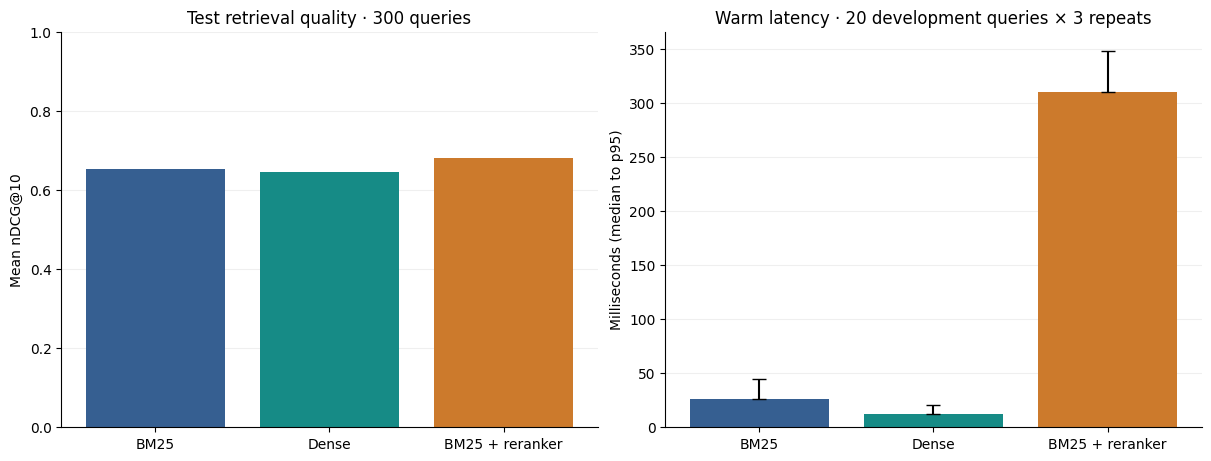

Development queries with the largest absolute reranking changes:


,query_id,relevant_doc_ids,bm25_candidate_recall50,bm25_top1,bm25_ndcg10,dense_top1,dense_ndcg10,bm25_reranked_top1,bm25_reranked_ndcg10,rerank_minus_bm25_ndcg10,my_observation
0,1139,12009265,1.0,25513319,0.3010,308862,0.6309,12009265,1.0000,0.6990,
1,498,17077004,1.0,13906581,0.3333,17077004,1.0000,17077004,1.0000,0.6667,
2,391,1148122,1.0,21602220,0.5000,21602220,0.6309,21602220,0.0000,-0.5000,
3,310,6173523,1.0,14464451,0.3869,14464451,0.0000,32770503,0.0000,-0.3869,
4,119,14606752,1.0,5691302,0.6309,14606752,1.0000,14606752,1.0000,0.3691,
5,12,33409100,1.0,11705328,0.6309,33409100,1.0000,33409100,1.0000,0.3691,
6,1293,43329366,1.0,380526,0.6309,43329366,1.0000,43329366,1.0000,0.3691,
7,164,5824985,1.0,18872233,0.6309,2058909,0.6309,5824985,1.0000,0.3691,
8,168,5824985,1.0,7627167,0.6309,5824985,1.0000,5824985,1.0000,0.3691,
9,306,7821634,1.0,7821634,1.0000,7821634,1.0000,10852047,0.6309,-0.3691,


In [11]:
comparisons = []
for baseline, comparison in [("bm25", "dense"), ("bm25", "bm25_reranked"), ("dense", "bm25_reranked")]:
    comparisons.append({
        "baseline": baseline, "comparison": comparison, "metric": "ndcg@10",
        "statistics": paired_bootstrap(test_per_method[baseline], test_per_method[comparison],
                                       seed=CONFIG["seed"], repeats=CONFIG["bootstrap_repeats"]),
    })
write_json(ARTIFACTS / "test_paired_comparisons.json", comparisons)
comparison_table = [{"baseline": r["baseline"], "comparison": r["comparison"], **r["statistics"]} for r in comparisons]
write_csv(ARTIFACTS / "test_paired_comparisons.csv", comparison_table)
display(pd.DataFrame(comparison_table).round(4))

quality = pd.DataFrame(test_summary).set_index("method").loc[list(METHODS)]
latency = pd.DataFrame(latency_summary).set_index("method").loc[list(METHODS)]
labels = ["BM25", "Dense", "BM25 + reranker"]
colors = ["#365f91", "#168b86", "#cc7a2c"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].bar(labels, quality["ndcg@10"], color=colors)
axes[0].set(title="Test retrieval quality · 300 queries", ylabel="Mean nDCG@10", ylim=(0, 1))
upper = latency["p95_ms"].to_numpy() - latency["median_ms"].to_numpy()
axes[1].bar(labels, latency["median_ms"], color=colors,
            yerr=np.vstack([np.zeros(len(METHODS)), upper]), capsize=5)
axes[1].set(title="Warm latency · 20 development queries × 3 repeats", ylabel="Milliseconds (median to p95)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.savefig(ARTIFACTS / "quality_latency.png", dpi=180)
plt.show()

rows = error_worksheet(development_runs, development_qrels)
write_json(ARTIFACTS / "error_worksheet_numeric.json", rows)
write_csv(ARTIFACTS / "error_analysis.csv", rows)
print("Development queries with the largest absolute reranking changes:")
display(pd.DataFrame(rows).head(10).round(4))

## 10. Inspect a chosen development example

The worksheet has IDs and scores, with blank observations. A large gain/loss identifies an
example to inspect; it does not explain the cause. Check whether the relevant document was
in the candidate pool, whether a query uses technical terms or paraphrases, and whether
truncation could matter. Do not infer causation from a single example.

To inspect one, enter a development query ID below and enable the switch. The optional
display shows its claim, relevant document IDs, and the top three documents from each method.
Raw benchmark text is not included in the default exported results.

In [12]:
SHOW_REVIEW_TEXT = False
REVIEW_QUERY_ID = None

if SHOW_REVIEW_TEXT:
    qid = str(REVIEW_QUERY_ID)
    if qid not in development_qrels:
        raise ValueError("Choose a query_id from the development error worksheet.")
    text_by_id = dict(zip(data["ids"], data["texts"]))
    print("Query:", data["queries"][qid])
    print("Judged relevant IDs:", development_qrels[qid])
    for method in METHODS:
        print("\n", method)
        for rank, did in enumerate(development_runs[method][qid]["ids"][:3], start=1):
            print(rank, did, "judged_relevant=", did in development_qrels[qid])
            print(text_by_id[did])

## 11. Verify and export the evidence

This check reloads the rankings and recomputes the quality tables, per-query metrics,
bootstrap comparisons, latency summaries, candidate membership, and file hashes.
It verifies consistency of the saved evidence; it does not independently repeat inference
or establish that every benchmark relevance judgment is complete or correct.

The ZIP contains the frozen protocol, source hashes, machine/software details, rankings,
qrels, charts, timing samples, error worksheet, and the helper module. Models and corpus
text are excluded. A result file marked `passed` is created only after checks succeed.

In [13]:
write_json(ARTIFACTS / "run_status.json", {
    "run_id": RUN_ID, "status": "completed", "benchmark": "BEIR SciFact",
    "development_queries": len(development_ids), "test_queries": len(test_ids),
    "methods": list(METHODS), "model_training_performed": False,
})
build_manifest(ARTIFACTS)
verification = verify_result_directory(ARTIFACTS)
write_json(ARTIFACTS / "verification.json", verification)
# Include the verification record itself in the final manifest.
build_manifest(ARTIFACTS)
print(json.dumps(verification, indent=2))

archive_path = shutil.make_archive(str(ARTIFACTS), "zip", root_dir=ARTIFACTS.parent, base_dir=ARTIFACTS.name)
print("Saved results:", archive_path)
try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    print("Outside Colab: download the ZIP from the notebook file browser.")

{
  "status": "passed",
  "query_method_rankings": 1050,
  "methods": [
    "bm25",
    "dense",
    "bm25_reranked"
  ],
  "latency_trials": 180,
  "hashed_files": 33,
  "scope": "Saved evidence consistency; not a repeat of model inference or a relevance-label audit."
}
Saved results: /content/artifacts/search_20261118T185027Z-4f8afe.zip


## Explain the experiment

Use your own measured outputs to answer these questions before the final write-up:

1. Which pipeline has the highest test nDCG@10? How large is the difference?
2. How do Recall@10 and MRR@10 support or complicate that result?
3. How much additional median and p95 latency does reranking cost on this machine?
4. Why must BM25 and BM25 + reranker have identical Recall@50 here?
5. Why does a high cosine similarity or reranker logit not prove a document is relevant?
6. What do the truncation counts imply for interpreting this comparison?
7. Show one improvement and one failure from development examples, if both exist.
8. What remains untested: generated answers, other domains/corpora, other models, candidate
   sizes, concurrent users, and production costs?

### Sources and attribution
- Alammar, J., & Grootendorst, M. (2024). *Hands-On Large Language Models*,
  [Chapter 8 code](https://github.com/HandsOnLLM/Hands-On-Large-Language-Models/tree/main/chapter08), Apache-2.0.
- Thakur et al. (2021). [BEIR](https://arxiv.org/abs/2104.08663).
- Wadden et al. (2020). [Fact or Fiction: Verifying Scientific Claims](https://aclanthology.org/2020.emnlp-main.609/).
- [SciFact corpus/queries](https://huggingface.co/datasets/BeIR/scifact) and
  [relevance judgments](https://huggingface.co/datasets/BeIR/scifact-qrels), CC BY-SA 4.0 as listed by the dataset repositories.
- [Embedding model](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
  [reranker](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2), and
  [Sentence Transformers documentation](https://www.sbert.net/docs/cross_encoder/usage/usage.html).

The notebook and utilities are a substantially changed experimental extension, with new
benchmark loading, metrics, timing, audits, and exports. See `ATTRIBUTION.md` and `LICENSE`
in the companion package. The code license does not replace the separate data/model terms.

## Interpretation of selected development errors

Five development queries were inspected to illustrate gains, ordering errors, and candidate misses.
They are selected examples, not a random sample of causes. Observations and reference-document ranks
are in [analysis/error_analysis.csv](analysis/error_analysis.csv). The original 50-row worksheet is preserved unchanged.
No relevance labels were edited and no independent annotation-reliability study was performed.

| Development query | Relevant-document ranks: BM25 → reranked (dense) | Observation |
|---|---|---|
| 1139 | 9 → 1 (2) | Reranking promoted the trial abstract relevant to the information need. |
| 498 | 7 → 1 (1) | Both neural pipelines found relevant counterevidence; relevance does not imply the query claim is true. |
| 391 | 3 → 14 (2) | Reranking moved a retrieved relevant document out of the top 10. |
| 310 | 5 → 13 (>50) | A reranker ordering error and a dense candidate miss on the same query. |
| 1109 | >50 → >50 (>50), for both relevant documents | Both initial retrieval methods missed the judged documents; reordering BM25's pool could not recover them. |

These rank changes are observable. Topical overlap and input truncation are possible contributors,
but this experiment does not establish their causal role in an individual error.

## Limits of the recorded comparison

The dense encoder uses at most **256 tokens** and truncated **3,681 of 5,183 documents (71.02%)**.
Reranking uses at most **512 tokens per query/document pair** and truncated **2,037 of 15,000 test pairs (13.58%)**
and **289 of 2,500 development pairs (11.56%)**. No evaluated dense query was truncated.
BM25 uses full title-plus-abstract text. These are comparisons of the declared pipelines,
not an isolated causal test of keyword versus neural architectures or the effect of truncation.

BM25 runs on CPU through `rank-bm25`; neural inference uses a Tesla T4, with dense vector comparison on CPU.
The dense pipeline's observed speed advantage is specific to this implementation, corpus, and hardware.
Warm timings exclude downloads, loading, and document indexing, and do not establish concurrent-user
throughput or production latency. Twenty queries repeated three times are not 60 independent queries.

The benchmark's judgments may be incomplete: unjudged documents score as nonrelevant without proving
they are irrelevant. Model pretraining exposure was not audited. Bootstrap intervals describe query
sampling conditional on this corpus, models, and labels; they exclude annotation uncertainty, hardware
variation, and domain shift. The three comparisons are descriptive and not adjusted for multiple testing.
No generated-answer accuracy, claim truth, or performance on policy/maritime documents was measured.
